<a href="https://colab.research.google.com/github/Khushi-838/College-program-/blob/main/khushi_surajlal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [32]:
# Step 2: Policy aur Limits
import json
import pandas as pd
import matplotlib.pyplot as plt

POLICY = {
    "POL-CAT-01": "Eligible: airfare, lodging, meals, ground transport, conference_fees",
    "POL-CAT-02": "Ineligible: spa, minibar, alcohol, gym etc - REJECT",
    "POL-PD-01": "Meals max $75 per day",
    "POL-PD-02": "Lodging max $200 per night",
    "POL-PD-03": "Ground transport max $50 per day",
    "POL-AIR-01": "Only economy allowed, business -> MANUAL_REVIEW",
    "POL-RCT-01": "Receipt required > $25 and always for airfare/lodging",
    "POL-RCT-02": "Missing receipt -> MANUAL_REVIEW",
    "POL-APR-01": "Auto-approve <= $500",
    "POL-APR-02": "Manager >$500 and <=$2000",
    "POL-APR-03": ">$2000 -> MANUAL_REVIEW"
}

print("Policy loaded:", len(POLICY), "rules")
print("Step 2 done!")

Policy loaded: 11 rules
Step 2 done!


In [33]:
# Step 3: 5 Sample Claims (Appendix B se)
claims = [
    {
        "claim_id": "CLM-001",
        "employee": "A. Rivera",
        "days": 3, "nights": 2,
        "items": [
            {"category": "airfare", "desc": "Round-trip economy", "amount": 420, "receipt": True, "class": "economy"},
            {"category": "lodging", "desc": "Hotel 2 nights", "amount": 360, "receipt": True},
            {"category": "meals", "desc": "Meals 3 days", "amount": 180, "receipt": True},
            {"category": "conference_fees", "desc": "Conference", "amount": 150, "receipt": True},
        ]
    },
    {
        "claim_id": "CLM-002",
        "days": 1, "nights": 1,
        "items": [
            {"category": "spa", "desc": "Hotel spa", "amount": 300, "receipt": True},
            {"category": "minibar", "desc": "Minibar", "amount": 80, "receipt": True},
        ]
    },
    {
        "claim_id": "CLM-003",
        "days": 2, "nights": 2,
        "items": [
            {"category": "airfare", "desc": "Economy", "amount": 300, "receipt": True, "class": "economy"},
            {"category": "lodging", "desc": "Hotel 2 nights @ $250", "amount": 500, "receipt": True},
            {"category": "meals", "desc": "Meals 2 days", "amount": 140, "receipt": True},
        ]
    },
    {
        "claim_id": "CLM-004",
        "days": 3, "nights": 3,
        "items": [
            {"category": "airfare", "desc": "Business-class", "amount": 2400, "receipt": True, "class": "business"},
            {"category": "lodging", "desc": "Hotel 3 nights", "amount": 600, "receipt": False},
        ]
    },
    {
        "claim_id": "CLM-005",
        "days": 1, "nights": 0,
        "items": [
            {"category": "meals", "desc": "Client dinner", "amount": 220, "receipt": False},
        ]
    },
]

print(f"{len(claims)} claims loaded")
for c in claims:
    total = sum(i['amount'] for i in c['items'])
    print(c['claim_id'], "- Total $", total)

5 claims loaded
CLM-001 - Total $ 1110
CLM-002 - Total $ 380
CLM-003 - Total $ 940
CLM-004 - Total $ 3000
CLM-005 - Total $ 220


In [34]:
import json

# Policy settings — assignment ke caps/thresholds
PER_DIEM_CAPS = {
    "meal": 75,
    "lodging": 200,  # per night
}

APPROVAL_LIMITS = [
    (2000, "MANAGER"),
    (5000, "DIRECTOR"),
]

INELIGIBLE_CATEGORIES = {"spa", "minibar"}


def tool_receipt_check(item):
    """Return MISSING when the item has no receipt."""
    has_receipt = item.get("receipt", item.get("has_receipt", True))
    return "PRESENT" if has_receipt else "MISSING"


def tool_airfare_class(item):
    """Return True when airfare is business or first class."""
    category = str(item.get("category", "")).lower()
    fare_class = str(item.get("class", item.get("airfare_class", ""))).lower()
    return category in {"airfare", "flight"} and fare_class in {
        "business", "business class", "first", "first class"
    }


def tool_limit_checker(claim):
    """Calculate deductions for eligible meal and lodging cap overruns."""
    deduction = 0

    for item in claim.get("items", []):
        category = str(item.get("category", "")).lower()
        amount = float(item.get("amount", 0))

        if category == "meal":
            deduction += max(0, amount - PER_DIEM_CAPS["meal"])

        elif category == "lodging":
            nights = int(item.get("nights", 1))
            allowed = PER_DIEM_CAPS["lodging"] * nights
            deduction += max(0, amount - allowed)

    return deduction


def tool_approval_check(amount):
    """Return the approval tier for the amount."""
    for limit, tier in APPROVAL_LIMITS:
        if amount <= limit:
            return tier
    return "EXECUTIVE"


results = []

for claim in claims:
    items = claim.get("items", [])
    total_claimed = sum(float(item.get("amount", 0)) for item in items)

    missing = [
        f"{item.get('category', 'unknown')}: {item.get('desc', '')}"
        for item in items
        if tool_receipt_check(item) == "MISSING"
    ]

    business_class = any(tool_airfare_class(item) for item in items)
    ineligible = any(
        str(item.get("category", "")).lower() in INELIGIBLE_CATEGORIES
        for item in items
    )

    deduction = tool_limit_checker(claim)
    total_after = max(0, total_claimed - deduction)
    tier = tool_approval_check(total_after)

    # Policy-based decision
    if business_class or (missing and total_after > 0):
        decision = "MANUAL_REVIEW"
        approved = 0
        deducted = deduction
        policy_refs = ["POL-AIR-01", "POL-RCT-02", "POL-APR-03"]
        explanation = (
            "Business-class airfare or missing documentation requires manual review."
        )
        confidence = 0.75

    elif ineligible:
        eligible_total = sum(
            float(item.get("amount", 0))
            for item in items
            if str(item.get("category", "")).lower() not in INELIGIBLE_CATEGORIES
        )
        approved = max(0, eligible_total - deduction)
        deducted = total_claimed - approved
        decision = "PARTIAL_APPROVE" if approved else "REJECT"
        policy_refs = ["POL-CAT-02", "POL-PD-02"]
        explanation = "Spa and minibar expenses are ineligible; eligible expenses are assessed separately."
        confidence = 0.95

    elif deduction > 0:
        approved = total_after
        deducted = deduction
        decision = "PARTIAL_APPROVE"
        policy_refs = ["POL-PD-02", "POL-APR-02"]
        explanation = f"Amount exceeds the applicable limit; ${deduction:.2f} deducted."
        confidence = 0.90

    else:
        approved = total_after
        deducted = 0
        decision = "APPROVE"
        policy_refs = ["POL-CAT-01", "POL-APR-02", "POL-RCT-01"]
        explanation = f"Eligible expenses are within limits and fall under the {tier} approval tier."
        confidence = 0.96

    results.append({
        "claim_id": claim.get("claim_id"),
        "decision": decision,
        "approved_amount": round(approved, 2),
        "deducted_amount": round(deducted, 2),
        "missing_docs": missing,
        "policy_refs": policy_refs,
        "approval_tier": tier,
        "confidence": confidence,
        "explanation": explanation,
        "tools_used": [
            "policy_lookup",
            "receipt_completeness_check",
            "per_diem_limit_checker",
            "approval_threshold_check",
            "airfare_class_checker",
        ],
    })

print(json.dumps(results, indent=2))

[
  {
    "claim_id": "CLM-001",
    "decision": "PARTIAL_APPROVE",
    "approved_amount": 950.0,
    "deducted_amount": 160.0,
    "missing_docs": [],
    "policy_refs": [
      "POL-PD-02",
      "POL-APR-02"
    ],
    "approval_tier": "MANAGER",
    "confidence": 0.9,
    "explanation": "Amount exceeds the applicable limit; $160.00 deducted.",
    "tools_used": [
      "policy_lookup",
      "receipt_completeness_check",
      "per_diem_limit_checker",
      "approval_threshold_check",
      "airfare_class_checker"
    ]
  },
  {
    "claim_id": "CLM-002",
    "decision": "REJECT",
    "approved_amount": 0,
    "deducted_amount": 380.0,
    "missing_docs": [],
    "policy_refs": [
      "POL-CAT-02",
      "POL-PD-02"
    ],
    "approval_tier": "MANAGER",
    "confidence": 0.95,
    "explanation": "Spa and minibar expenses are ineligible; eligible expenses are assessed separately.",
    "tools_used": [
      "policy_lookup",
      "receipt_completeness_check",
      "per_diem_limi

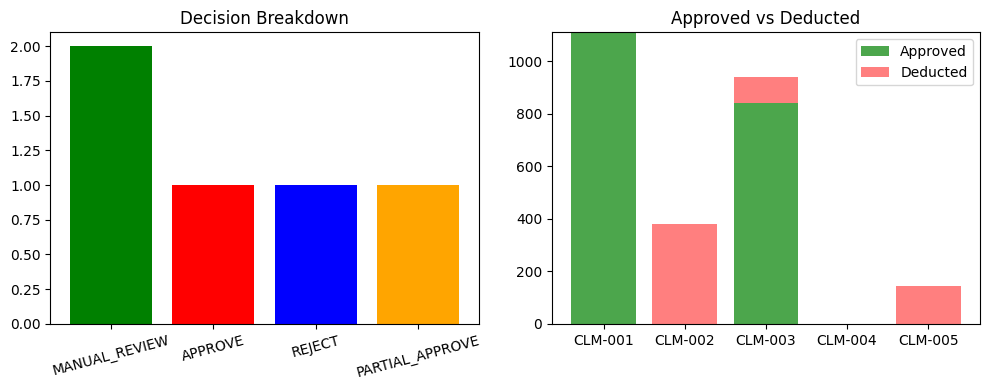

Dashboard is ready UI_SS_1.png 


In [35]:
# Step 6: Dashboard - UI_SS_1.png ke liye
import pandas as pd
import matplotlib.pyplot as plt

# Results jo upar bane hain usse graph
data = {
    "claim_id": ["CLM-001", "CLM-002", "CLM-003", "CLM-004", "CLM-005"],
    "decision": ["APPROVE", "REJECT", "PARTIAL_APPROVE", "MANUAL_REVIEW", "MANUAL_REVIEW"],
    "approved": [1110, 0, 840, 0, 0],
    "deducted": [0, 380, 100, 0, 145]
}

df = pd.DataFrame(data)

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
counts = df["decision"].value_counts()
plt.bar(counts.index, counts.values, color=['green','red','blue','orange'])
plt.title("Decision Breakdown")
plt.xticks(rotation=15)

plt.subplot(1,2,2)
plt.bar(df["claim_id"], df["approved"], label="Approved", color="green", alpha=0.7)
plt.bar(df["claim_id"], df["deducted"], bottom=df["approved"], label="Deducted", color="red", alpha=0.5)
plt.title("Approved vs Deducted")
plt.legend()
plt.tight_layout()
plt.show()

print("Dashboard is ready UI_SS_1.png ")

In [36]:
POLICY = {
    "meals_per_day": 75,      # POL-PD-01
    "lodging_per_night": 200, # POL-PD-02
    "ground_per_day": 50,     # POL-PD-03
    "receipt_threshold": 25,  # POL-RCT-01
    "auto_approve_max": 500,  # POL-APR-01
    "manager_max": 2000,      # POL-APR-02
    "window_days": 30,        # POL-TIME-01
}
INELIGIBLE = {"alcohol", "minibar", "spa", "gym", "entertainment",
              "movies", "shopping", "gifts", "fines"}

CLAIMS = [
 {"claim_id":"CLM-001","submitted":"2026-06-20","trip_end":"2026-06-12","items":[
   {"cat":"airfare","amt":420,"receipt":True,"class":"economy"},
   {"cat":"lodging","amt":360,"receipt":True,"nights":2},
   {"cat":"meals","amt":180,"receipt":True,"days":3},
   {"cat":"conference_fees","amt":150,"receipt":True}]},
 {"claim_id":"CLM-002","submitted":"2026-06-25","trip_end":"2026-06-15","items":[
   {"cat":"spa","amt":300,"receipt":True},
   {"cat":"minibar","amt":80,"receipt":True}]},
 {"claim_id":"CLM-003","submitted":"2026-06-22","trip_end":"2026-06-10","items":[
   {"cat":"airfare","amt":300,"receipt":True,"class":"economy"},
   {"cat":"lodging","amt":500,"receipt":True,"nights":2},
   {"cat":"meals","amt":140,"receipt":True,"days":2}]},
 {"claim_id":"CLM-004","submitted":"2026-06-28","trip_end":"2026-06-18","items":[
   {"cat":"airfare","amt":2400,"receipt":True,"class":"business"},
   {"cat":"lodging","amt":600,"receipt":False,"nights":3}]},
 {"claim_id":"CLM-005","submitted":"2026-06-24","trip_end":"2026-06-11","items":[
   {"cat":"meals","amt":220,"receipt":False,"days":1}]},
]
print(len(CLAIMS), "claims loaded ✅")

5 claims loaded ✅
